# Run quality control (all subjects) and effect on the OD results

**Why.** In sub-05, the amblyopic-eye Bars01 run (first functional run of the session) has almost no signal (R² 0.05 vs 0.4-0.67 for the other runs) and reverses the OD of its stimulus (`od_sub05_investigation.ipynb`). Removing that run only in sub-05 would be ad hoc: a run must be excluded by a **criterion fixed in advance and applied to every subject**.

**Measure per run** (8 runs per subject: 4 stimuli × 2 eyes): weighted median, over the selected V1-V3 vertices (v9 selection and weight), of the R² of the run with its own eye's pRF prediction. Also the β (common regressor), the acquisition position and the head motion (mean framewise displacement, fMRIPrep).

**Criterion (fixed before looking at the OD):** a run is **bad** if its R² is **< 50 % of the median R² of the 7 other runs of the same subject** (relative criterion: the overall quality differs a lot between subjects, so an absolute threshold would exclude whole subjects such as sub-04). Sensitivity: 33 % and 67 %.

**Exclusion:** when a run is bad, the **pair of runs of that stimulus is removed for both eyes** (each eye keeps the same stimuli, so the OD is not biased by a stimulus composition that differs between eyes). Variant: removing the bad run only.

**Effect on the results:** Figure 1 measure (% of vertices preferring FE) and Figure 2 measure (weighted median of the vertex OD index), recomputed from the per-run GLM sums without the excluded runs; same tests as v9 (Wilcoxon, FDR over the 8 ROIs). Limit: the pRF fits (vertex selection, weights, regressor) still include the bad runs; a full re-analysis would refit without them.

Read only; figures in `Desktop/fig_od` (prefix `runqc_`).

## Setup (cells copied from v9)

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import numpy as np
import pandas as pd
from scipy import stats, integrate
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex
from plot_utils import plotly_template

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od'
cache_dir = '/Users/uriel/Desktop/fig_od/od_glm_common_cache'       # per-run GLM sums (od_glm_common_analysis.ipynb)
os.makedirs(fig_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
controls = analysis_info['group-control']
subjects = analysis_info['subjects']
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_css_od = analysis_info['maps_names_css_od']

# Analysis
task = 'BarsBarsRingsWedges'
file_spec = '{}/{}/fsnative/prfmodel/prf_derivatives/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_{}.func.gii'
rois_to_keep = ['V1', 'V2', 'V3', 'V4', 'V3A', 'V3B', 'LO1', 'LO2']
eyes = {'L': 'LeftEye', 'R': 'RightEye'}

# prf_analysis filters (applied to both eyes)
ecc_th = analysis_info['ecc_th']
size_th = analysis_info['size_th']
n_th = analysis_info['n_th']
rsqr_th = analysis_info['rsqr_th']
amp_th = analysis_info['prf_amp_th']
amp_th = amp_th['psc'] if isinstance(amp_th, dict) else amp_th
stats_th = analysis_info['stats_th']
p_name = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'

# Amblyopic eye of each patient
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e).split(' ')[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)
             if str(e).split(' ')[0] in ('L', 'R')}

# Eye scanned first (read only: sourcedata/participant-mapping.md + participant_mapping.tsv)
src_dir = '{}/{}/sourcedata'.format(main_dir, project_dir)
mapping = pd.read_csv('{}/participant_mapping.tsv'.format(src_dir), sep='\t', dtype=str).dropna(subset=['initials'])
initials_to_sub = {i.strip(): b.strip() for i, b in zip(mapping.initials, mapping.bids_name)}
first_eye = {}
with open('{}/participant-mapping.md'.format(src_dir)) as f:
    for line in f:
        if 'eye first' in line:
            initials, txt = line.split(',', 1)
            first_eye[initials_to_sub[initials.strip()]] = 'L' if 'LEFT' in txt.upper() else 'R'

# Pycortex database (ROIs)
cortex_dir = '{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)

In [3]:
def bh_fdr(p):
    """Benjamini-Hochberg FDR correction."""
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = p[o] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[o] = np.minimum(q, 1)
    return out


def wcorr(x, y, w):
    """Weighted rank correlation: Pearson correlation of the ranks of x and y, each vertex weighted by w."""
    x, y, w = stats.rankdata(x), stats.rankdata(y), np.asarray(w, float)
    if np.sum(w) == 0:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''


def bf10_ttest(x, h0=0, r=np.sqrt(2) / 2):
    """JZS Bayes factor BF10 of a one-sample t-test (Rouder et al. 2009), Cauchy prior of scale r on the effect size."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)] - h0
    n, v = x.size, x.size - 1
    t = x.mean() / (x.std(ddof=1) / np.sqrt(n))
    null = (1 + t ** 2 / v) ** (-(v + 1) / 2)
    alt = integrate.quad(lambda g: (1 + n * g * r ** 2) ** -0.5
                         * (1 + t ** 2 / ((1 + n * g * r ** 2) * v)) ** (-(v + 1) / 2)
                         * (2 * np.pi) ** -0.5 * g ** -1.5 * np.exp(-1 / (2 * g)), 0, np.inf)[0]
    return alt / null


def within_tests(df, value, h0, alt_patient='greater', alt_control='two-sided'):
    """Per ROI: Wilcoxon of each group vs h0 (FDR over the ROIs) + Bayes factor BF01 of the controls."""
    rows = []
    for roi in rois_to_keep:
        d = df[df.roi == roi]
        vp, vc = d[d.group == 'patient'][value].dropna(), d[d.group == 'control'][value].dropna()
        rows.append({'roi': roi, 'median_patients': vp.median(), 'median_controls': vc.median(),
                     'p_patients': stats.wilcoxon(vp - h0, alternative=alt_patient).pvalue,
                     'p_controls': stats.wilcoxon(vc - h0, alternative=alt_control).pvalue,
                     'BF01_controls': 1 / bf10_ttest(vc, h0)})
    s = pd.DataFrame(rows).set_index('roi')
    s['p_patients_fdr'] = bh_fdr(s.p_patients)
    s['p_controls_fdr'] = bh_fdr(s.p_controls)
    return s


# Figure settings (as the other pRF figures)
template_specs = dict(axes_color="rgba(0, 0, 0, 1)", axes_width=2, axes_font_size=15,
                      bg_col="rgba(255, 255, 255, 1)", font='Arial', title_font_size=15, rois_plot_width=1.5)
fig_template = plotly_template(template_specs)
roi_colors_rgb = analysis_info['roi_colors']
fig_margin = analysis_info['rois_fig_margin']
bar_width = analysis_info['rois_bar_width']
rois_plot_height = analysis_info['rois_plot_height']
rois_hor_spacing = 50
ctrl_color = 'rgb(150,150,150)'
groups = ['patient', 'control']
group_labels = {'patient': 'Amblyopes', 'control': 'Controls'}
cols = len(rois_to_keep)
fig_height = rois_plot_height * 2 + fig_margin[1] + fig_margin[3]
fig_width = bar_width * 4 * cols + fig_margin[0] + fig_margin[2] + (rois_hor_spacing * (cols - 1))
hor_spacing = rois_hor_spacing / (fig_width - fig_margin[0] - fig_margin[2])


def bar_figure(df, values, s, y_title, y_ticks, tick_fmt, fn_out, legends=None, patterns=None):
    """Median and 25-75 percentiles per group and ROI; stars = within-group test of s (FDR)."""
    patterns = patterns or [''] * len(values)
    y_step = (y_ticks[-1] - y_ticks[0]) * 0.05
    fig = make_subplots(rows=1, cols=cols, subplot_titles=rois_to_keep, horizontal_spacing=hor_spacing)
    for col_idx, roi in enumerate(rois_to_keep, start=1):
        d = df[df.roi == roi]
        top = {group: -np.inf for group in groups}
        for value, pattern in zip(values, patterns):
            med, p25, p75 = [], [], []
            for group in groups:
                v = d[d.group == group][value].dropna()
                med.append(v.median()); p25.append(np.nanpercentile(v, 25)); p75.append(np.nanpercentile(v, 75))
                top[group] = max(top[group], np.nanpercentile(v, 75), v.median(), 0)
            med, p25, p75 = np.array(med), np.array(p25), np.array(p75)
            fig.add_trace(go.Bar(x=[group_labels[g] for g in groups], y=med, offsetgroup=value,
                                 marker=dict(color=[roi_colors_rgb[roi], ctrl_color],
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0)', size=8)),
                                 error_y=dict(type='data', array=p75 - med, arrayminus=med - p25, visible=True,
                                              thickness=2, width=0, color='rgba(0,0,0,1)'),
                                 showlegend=False),
                          row=1, col=col_idx)
        xref, yref = 'x{}'.format('' if col_idx == 1 else col_idx), 'y{}'.format('' if col_idx == 1 else col_idx)
        for x_pos, group in enumerate(groups):
            p = s.loc[roi, 'p_{}_fdr'.format('patients' if group == 'patient' else 'controls')]
            fig.add_annotation(x=x_pos, y=top[group] + y_step / 2, xref=xref, yref=yref, text=stars(p),
                               showarrow=False, font=dict(size=16, color='black'), yanchor='bottom')
        fig.add_shape(type='line', x0=0, x1=0, y0=y_ticks[0], y1=y_ticks[-1], xref='{} domain'.format(xref), yref=yref,
                      line=dict(color=template_specs['axes_color'], width=template_specs['axes_width']))
    if legends:
        for legend, pattern in zip(legends, patterns):
            fig.add_trace(go.Bar(x=[None], y=[None], name=legend,
                                 marker=dict(color='rgba(128,128,128,1)',
                                             pattern=dict(shape=pattern, fgcolor='rgba(0,0,0,1)',
                                                          bgcolor='rgba(0,0,0,0.3)', size=8)),
                                 showlegend=True), row=1, col=1)
    fig.update_xaxes(showline=True, ticklen=0, linecolor='rgba(255,255,255,0)', tickangle=0)
    fig.update_yaxes(showline=False, range=[y_ticks[0], y_ticks[-1] + 3 * y_step], tickvals=y_ticks,
                     ticktext=[tick_fmt.format(t) for t in y_ticks], showticklabels=True)
    fig.update_yaxes(title_text=y_title, row=1, col=1)
    fig.update_layout(barmode='group', bargap=0.3, bargroupgap=0.05, height=fig_height, width=fig_width,
                      template=fig_template,
                      legend=dict(orientation='h', font_family=template_specs['font'],
                                  font_size=template_specs['axes_font_size'], x=1, y=1.15, xanchor='right',
                                  yanchor='bottom', bgcolor='rgba(0,0,0,0)', traceorder='normal', itemwidth=30),
                      margin_l=fig_margin[0], margin_t=fig_margin[1] + 40, margin_r=fig_margin[2], margin_b=fig_margin[3])
    fig.show()
    fig.write_image('{}/{}.pdf'.format(fig_dir, fn_out))


def nice_ticks(values, step):
    lo = min(0, np.floor(np.nanmin(values) / step) * step)
    hi = max(step, np.ceil(np.nanmax(values) / step) * step)
    return np.round(np.arange(lo, hi + step / 2, step), 3)


def wpearson(x, y, w):
    """Weighted Pearson correlation (= correlation of a weighted linear regression)."""
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    if np.sum(w) == 0 or len(x) < 3:
        return np.nan
    mx, my = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    return np.sum(w * (x - mx) * (y - my)) / np.sqrt(np.sum(w * (x - mx) ** 2) * np.sum(w * (y - my) ** 2))


def deming(x, y, w=None):
    """Weighted Deming (orthogonal) regression, as in make_corr_tsv.py: returns slope, intercept.
    Symmetric in x and y (both halves are measured with noise), weights normalised to sum 1."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(w)
    x, y, w = x[ok], y[ok], w[ok]
    if len(x) < 3 or np.sum(w) == 0:
        return np.nan, np.nan
    w = w / np.sum(w)
    mx, my = np.sum(w * x), np.sum(w * y)
    sxx, syy, sxy = np.sum(w * (x - mx) ** 2), np.sum(w * (y - my) ** 2), np.sum(w * (x - mx) * (y - my))
    if sxy == 0:
        return np.nan, np.nan
    slope = (syy - sxx + np.sqrt((syy - sxx) ** 2 + 4 * sxy ** 2)) / (2 * sxy)
    return slope, my - slope * mx


def wmedian(x, w):
    """Weighted median: first value where the cumulative weight reaches half of the total."""
    x, w = np.asarray(x, float), np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(w) & (w > 0)
    if ok.sum() == 0:
        return np.nan
    o = np.argsort(x[ok])
    cw = np.cumsum(w[ok][o])
    return x[ok][o][np.searchsorted(cw, 0.5 * cw[-1])]


def od_index(b_fe, b_ae):
    """OD index (FE - AE) / (FE + AE); defined for positive betas only."""
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where((b_fe > 0) & (b_ae > 0), (b_fe - b_ae) / (b_fe + b_ae), np.nan)

In [4]:
# ---------- local cache of the vertex data (vertices of the 8 ROIs only)
vcache_dir = '{}/od_vertex_cache'.format(fig_dir)
os.makedirs(vcache_dir, exist_ok=True)
deriv_keys = ['prf_rsq', 'prf_ecc', 'prf_size', 'prf_n', 'amplitude', 'prf_x', 'prf_y']


def subject_files(subject):
    fns = [file_spec.format(pp_dir, subject, subject, task, '', hemi, 'od') for hemi in ['L', 'R']]
    for eye in eyes.values():
        for kind in ['deriv', 'stats']:
            fns += [file_spec.format(pp_dir, subject, subject, task, eye, hemi, kind) for hemi in ['L', 'R']]
    return fns


def load_subject(subject):
    """Vertex data of one subject: betas, pRF parameters and fit p-value of each eye, ROI masks (full-length arrays).
    Read from the local cache when it is newer than all the source files, otherwise from the data disks (then cached)."""
    fns = subject_files(subject)
    if not all(os.path.isfile(fn) for fn in fns):
        return None
    cache_fn = '{}/{}_od-vertex-cache.npz'.format(vcache_dir, subject)
    src_mtime = max(os.path.getmtime(fn) for fn in fns)
    if not (os.path.isfile(cache_fn) and float(np.load(cache_fn)['src_mtime']) >= src_mtime):
        od_mat = load_surface_pycortex(L_fn=fns[0], R_fn=fns[1])['data_concat']
        rois = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
        idx = np.where(np.any([rois[roi] for roi in rois_to_keep], axis=0))[0]
        save = {'n_vertices': od_mat.shape[1], 'idx': idx, 'src_mtime': src_mtime,
                'beta_L': od_mat[maps_names_css_od.index('od_beta_le')][idx].astype(np.float32),
                'beta_R': od_mat[maps_names_css_od.index('od_beta_re')][idx].astype(np.float32)}
        for roi in rois_to_keep:
            save['roi_{}'.format(roi)] = rois[roi][idx]
        for e, eye in eyes.items():
            deriv = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'deriv'),
                                          R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'deriv'))['data_concat']
            st = load_surface_pycortex(L_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'L', 'stats'),
                                       R_fn=file_spec.format(pp_dir, subject, subject, task, eye, 'R', 'stats'))['data_concat']
            for key in deriv_keys:
                save['{}_{}'.format(e, key)] = deriv[maps_names_css.index(key)][idx].astype(np.float32)
            save['{}_p'.format(e)] = st[maps_names_css_stats.index(p_name)][idx].astype(np.float32)
        np.savez_compressed(cache_fn, **save)
        print('{}: read from the data disks, cached'.format(subject), end=' | ')
    c = np.load(cache_fn)
    n, idx = int(c['n_vertices']), c['idx']

    def full(x, fill=np.nan):
        out = np.full(n, fill, dtype=float if fill is not False else bool)
        out[idx] = x
        return out
    return {'beta': {e: full(c['beta_{}'.format(e)]) for e in eyes},
            'd': {e: {key: full(c['{}_{}'.format(e, key)]) for key in deriv_keys} for e in eyes},
            'p': {e: full(c['{}_p'.format(e)]) for e in eyes},
            'rois': {roi: full(c['roi_{}'.format(roi)], False) for roi in rois_to_keep}}


def select(d, p):
    """prf_analysis filters of one eye + positive pRF amplitude (p = p-value of the pRF fit)."""
    with np.errstate(invalid='ignore'):
        return ((d['prf_ecc'] >= ecc_th[0]) & (d['prf_ecc'] <= ecc_th[1])
                & (d['prf_size'] >= size_th[0]) & (d['prf_size'] <= size_th[1])
                & (d['prf_n'] >= n_th[0]) & (d['prf_n'] <= n_th[1])
                & (d['prf_rsq'] >= rsqr_th)
                & (d['amplitude'] >= amp_th[0]) & (d['amplitude'] <= amp_th[1]) & (d['amplitude'] > 0)
                & (p <= stats_th))


def pref_percent(b_a, b_b, w):
    return 100 * np.sum(w * (b_a > b_b)) / np.sum(w) if np.sum(w) > 0 else np.nan


rows, vertex_data = [], {}
for subject in subjects:
    group = 'patient' if subject in patients else 'control'
    sd = load_subject(subject)
    if sd is None:
        print('{}: OD image or pRF files missing, skipped'.format(subject))
        continue
    beta = sd['beta']
    keep_eye = {e: select(sd['d'][e], sd['p'][e]) & np.isfinite(beta[e]) for e in eyes}
    rsq_eye = {e: sd['d'][e]['prf_rsq'] for e in eyes}
    weight = np.nan_to_num(np.clip(np.nanmean([rsq_eye['L'], rsq_eye['R']], axis=0), 0, None))   # mean pRF R² of both eyes

    # FE-LE / AE-RE: amblyopes -> fellow / amblyopic eye, controls -> left / right eye
    fe, ae = ('R', 'L') if ambly_eye.get(subject) == 'L' else ('L', 'R')
    b_fe, b_ae = beta[fe], beta[ae]
    keep = keep_eye['L'] & keep_eye['R']                            # pRF filters on both eyes, all betas kept
    vertex_data[subject] = {'fe': fe, 'keep': keep, 'w': weight}

    rois = sd['rois']
    for roi in rois_to_keep:
        mask = rois[roi] & keep
        w = weight[mask]
        if mask.sum() < 10 or np.sum(w) == 0:
            continue
        mask_fe, mask_ae = rois[roi] & keep_eye[fe], rois[roi] & keep_eye[ae]
        rows.append({'subject': subject, 'group': group, 'roi': roi, 'n_vertices': mask.sum(),
                     'fe_le_first': first_eye[subject] == fe,
                     # vertices with beta <= 0 (kept in Figure 1, excluded from the vertex OD index)
                     'neg_any_pct': 100 * np.mean((b_fe[mask] <= 0) | (b_ae[mask] <= 0)),
                     'neg_any_w_pct': 100 * np.sum(w * ((b_fe[mask] <= 0) | (b_ae[mask] <= 0))) / np.sum(w),
                     'neg_fe_only_pct': 100 * np.mean((b_fe[mask] <= 0) & (b_ae[mask] > 0)),
                     'neg_ae_only_pct': 100 * np.mean((b_ae[mask] <= 0) & (b_fe[mask] > 0)),
                     'neg_both_pct': 100 * np.mean((b_fe[mask] <= 0) & (b_ae[mask] <= 0)),
                     # measures
                     'pref_FE-LE': pref_percent(b_fe[mask], b_ae[mask], w),
                     'pref_AE-RE': pref_percent(b_ae[mask], b_fe[mask], w),
                     'od_index': wmedian(od_index(b_fe[mask], b_ae[mask]), w),     # weighted median of the vertex OD index (both β > 0)
                     # vertex-selection checks
                     'pref_fe_sel': pref_percent(b_fe[mask_fe], b_ae[mask_fe], weight[mask_fe]),
                     'pref_ae_sel': pref_percent(b_fe[mask_ae], b_ae[mask_ae], weight[mask_ae]),
                     'rsq_fe': np.nanmedian(rsq_eye[fe][mask]), 'rsq_ae': np.nanmedian(rsq_eye[ae][mask])})
    print('{}: done'.format(subject))
df_subjects = pd.DataFrame(rows)
df_subjects.groupby(['group', 'roi'])[['n_vertices', 'pref_FE-LE', 'od_index']].median().unstack('group').reindex(rois_to_keep).round(3)

sub-01: done
sub-02: done
sub-03: done
sub-04: done
sub-05: done
sub-06: done
sub-07: done
sub-08: done
sub-09: done
sub-10: done
sub-11: done
sub-12: done
sub-13: done
sub-14: done
sub-16: done
sub-17: done
sub-18: done
sub-19: done
sub-20: done
sub-21: done


n_vertices         pref_FE-LE         od_index        
group    control patient    control patient  control patient
roi                                                         
V1        5107.0  4320.5     51.398  57.927    0.009   0.037
V2        4681.5  4117.5     56.214  62.645    0.021   0.090
V3        3202.5  2960.0     56.632  69.918    0.030   0.145
V4        2646.0  2454.5     57.800  71.459    0.038   0.118
V3A        762.5  1000.5     53.220  70.811    0.006   0.147
V3B        305.0   509.0     46.095  83.305   -0.014   0.113
LO1        485.5   429.0     56.755  78.412    0.018   0.141
LO2        457.0   292.0     72.801  71.382    0.107   0.128

## Per-run measures

In [5]:
import glob
import matplotlib.pyplot as plt

run_names = ['Bars01', 'Bars02', 'Rings', 'Wedges']
all_runs = [0, 1, 2, 3]
early = ['V1', 'V2', 'V3']
thresholds = {'33 %': 0.33, '50 % (main)': 0.5, '67 %': 0.67}
main_th = '50 % (main)'


def load_runs(subject):
    fn = '{}/{}_od-glm-common_runs.npz'.format(cache_dir, subject)
    if not os.path.isfile(fn) or subject not in vertex_data:
        return None
    c = np.load(fn)
    vd = vertex_data[subject]
    fe_i, ae_i = (1, 0) if vd['fe'] == 'R' else (0, 1)
    with np.errstate(divide='ignore', invalid='ignore'):
        r2 = c['sxy_own'] ** 2 / (c['sxx_own'] * c['syy'])
    sxy = {'fe': c['sxy_common'][fe_i], 'ae': c['sxy_common'][ae_i]}
    ok = np.isfinite(sxy['fe']).all(0) & np.isfinite(sxy['ae']).all(0) & np.isfinite(c['sxx_common']).all(0)
    return {'sxy': sxy, 'sxx': c['sxx_common'], 'r2_run': {'fe': r2[fe_i], 'ae': r2[ae_i]},
            'keep': vd['keep'][c['vertex']] & ok, 'w': vd['w'][c['vertex']], 'roi': c['roi'], 'fe': vd['fe'],
            'group': 'patient' if subject in patients else 'control'}


def beta(R, eye, runs):
    runs = list(runs)
    with np.errstate(divide='ignore', invalid='ignore'):
        return R['sxy'][eye][runs].sum(0) / R['sxx'][runs].sum(0)


runs = {s: R for s in df_subjects.subject.unique() for R in [load_runs(s)] if R is not None}
subj_order = [s for s in patients + controls if s in runs]

# acquisition position (sourcedata BIDS conversion files) and head motion (fMRIPrep confounds)
sub_to_init = {v: k for k, v in initials_to_sub.items()}


def acq_positions(subject):
    init = sub_to_init.get(subject)
    fns = glob.glob('{}/{}/sourcedata/*/{}/bids_mapping_verification.txt'.format(main_dir, project_dir, init)) if init else []
    if not fns:
        return {}
    pos = {}
    with open(fns[0]) as f:
        for line in f:
            p = line.split()
            if len(p) >= 4 and p[0].isdigit() and p[3].startswith('task-'):
                pos[p[3].replace('_bold', '')] = int(p[1])
    return {k: i + 1 for i, k in enumerate(sorted(pos, key=pos.get))}


def task_name(eye_lr, k):
    stim, run = {'Bars01': ('Bars', '01'), 'Bars02': ('Bars', '02'), 'Rings': ('Rings', '01'), 'Wedges': ('Wedges', '01')}[run_names[k]]
    return 'task-{}{}Eye_run-{}'.format(stim, 'Left' if eye_lr == 'L' else 'Right', run)


def mean_fd(subject, tname):
    fns = glob.glob('{}/{}/derivatives/fmriprep/fmriprep/{}/ses-*/func/{}_ses-*_{}_desc-confounds_timeseries.tsv'.format(
        main_dir, project_dir, subject, subject, tname))
    if not fns:
        return np.nan
    return pd.read_csv(fns[0], sep='\t', usecols=['framewise_displacement']).framewise_displacement.mean()


rows = []
for s in subj_order:
    R = runs[s]
    m = R['keep'] & np.isin(R['roi'], early)
    pos = acq_positions(s)
    for eye, lr in [('fe', R['fe']), ('ae', 'L' if R['fe'] == 'R' else 'R')]:
        for k in all_runs:
            tn = task_name(lr, k)
            rows.append({'subject': s, 'group': R['group'], 'eye': eye.upper(), 'stim': run_names[k], 'k': k,
                         'position': pos.get(tn, np.nan), 'first_of_session': pos.get(tn, np.nan) == 1,
                         'r2_run': wmedian(R['r2_run'][eye][k][m], R['w'][m]),
                         'beta_run': wmedian(beta(R, eye, [k])[m], R['w'][m]), 'fd_mean': mean_fd(s, tn)})
qc = pd.DataFrame(rows)
qc['r2_others'] = [qc[(qc.subject == r.subject) & ~((qc.eye == r.eye) & (qc.k == r.k))].r2_run.median() for r in qc.itertuples()]
qc['r2_rel'] = qc.r2_run / qc.r2_others
for name, th in thresholds.items():
    qc['bad {}'.format(name)] = qc.r2_rel < th
print('{} runs ({} subjects)'.format(len(qc), qc.subject.nunique()))
for name in thresholds:
    print('Bad runs at {}: {}'.format(name, qc['bad {}'.format(name)].sum()))
print()
print(qc[qc['bad 67 %']].sort_values('r2_rel')[['subject', 'group', 'eye', 'stim', 'position', 'r2_run', 'r2_others', 'r2_rel',
                                                    'beta_run', 'fd_mean'] + ['bad {}'.format(n) for n in thresholds]].round(3).to_string(index=False))

160 runs (20 subjects)
Bad runs at 33 %: 20
Bad runs at 50 % (main): 30
Bad runs at 67 %: 48

subject   group eye   stim  position  r2_run  r2_others  r2_rel  beta_run  fd_mean  bad 33 %  bad 50 % (main)  bad 67 %
 sub-16 control  AE Bars01         2   0.009      0.498   0.018     0.074    0.119      True             True      True
 sub-16 control  AE Bars02         4   0.011      0.498   0.023     0.102    0.146      True             True      True
 sub-11 patient  AE Bars01         2   0.015      0.372   0.040     0.126    0.087      True             True      True
 sub-17 control  FE Bars02         8   0.028      0.665   0.043     0.217    0.140      True             True      True
 sub-14 control  AE Bars01         3   0.033      0.632   0.053     0.320    0.119      True             True      True
 sub-17 control  AE Bars02         4   0.039      0.665   0.059     0.362    0.202      True             True      True
 sub-14 control  FE Bars01         5   0.039      0.632   0.061   

### Figure Q1 — quality of every run

Left: relative R² of each run (subject × run; ✕ = bad at the main threshold). Right: distribution of the relative R² of the 160 runs with the 3 thresholds.

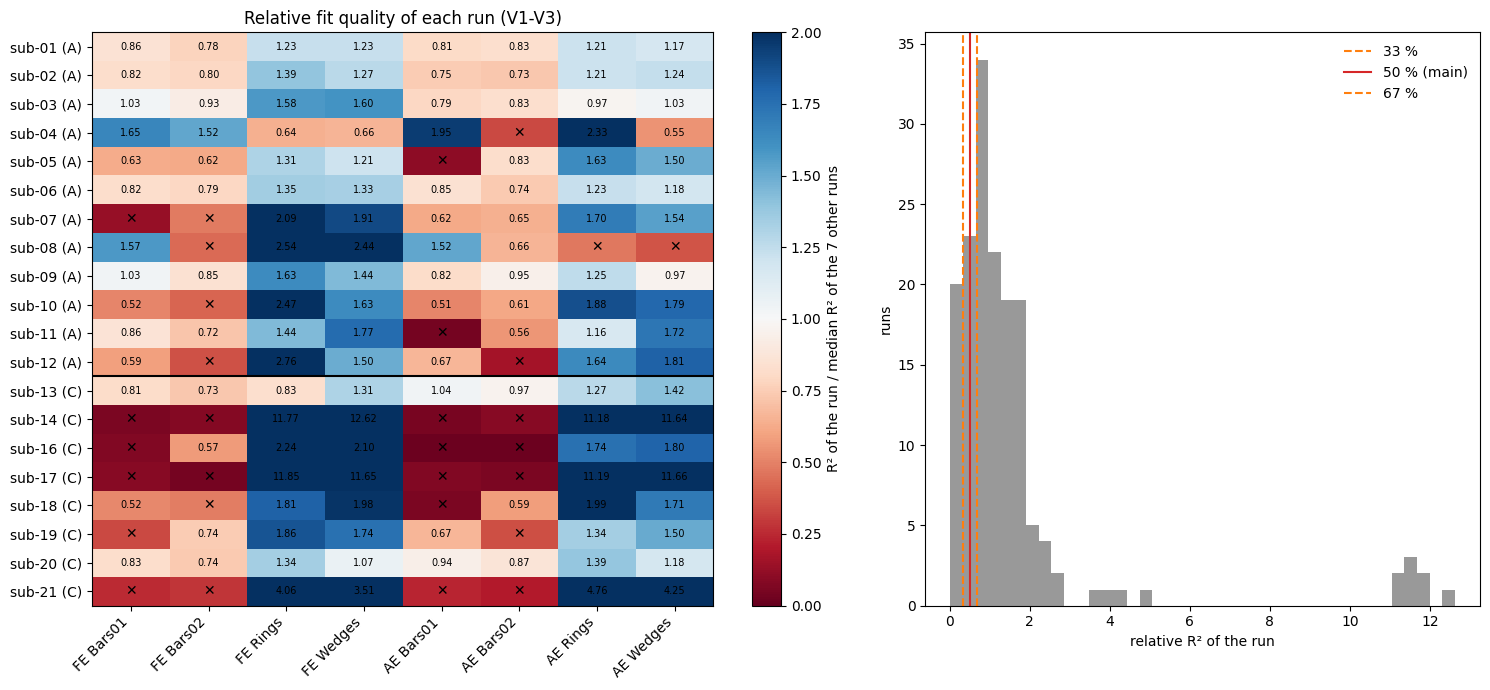

In [6]:
cols = ['{} {}'.format(e, n) for e in ['FE', 'AE'] for n in run_names]
piv = qc.assign(col=qc.eye + ' ' + qc.stim).pivot(index='subject', columns='col', values='r2_rel').reindex(index=subj_order, columns=cols)
bad = qc.assign(col=qc.eye + ' ' + qc.stim).pivot(index='subject', columns='col', values='bad {}'.format(main_th)).reindex(index=subj_order, columns=cols)
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.4, 1]})
ax = axes[0]
im = ax.imshow(piv.values, cmap='RdBu', vmin=0, vmax=2, aspect='auto')
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, '✕' if bad.values[i, j] else '{:.2f}'.format(piv.values[i, j]), ha='center', va='center',
                fontsize=10 if bad.values[i, j] else 7, fontweight='bold' if bad.values[i, j] else 'normal')
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha='right')
ax.set_yticks(range(len(subj_order))); ax.set_yticklabels(['{} ({})'.format(s, 'A' if s in patients else 'C') for s in subj_order])
ax.axhline(sum(s in patients for s in subj_order) - 0.5, color='k')
plt.colorbar(im, ax=ax, label='R² of the run / median R² of the 7 other runs')
ax.set_title('Relative fit quality of each run (V1-V3)')
ax = axes[1]
ax.hist(qc.r2_rel, bins=40, color='0.6')
for name, th in thresholds.items():
    ax.axvline(th, color='tab:red' if name == main_th else 'tab:orange', ls='-' if name == main_th else '--', label=name)
ax.set_xlabel('relative R² of the run'); ax.set_ylabel('runs'); ax.legend(frameon=False)
plt.tight_layout(); fig.savefig('{}/runqc_Q1_run_quality.pdf'.format(fig_dir), bbox_inches='tight'); plt.show()

### What goes with a bad run?

Relative R² vs acquisition position (is the first run of the session worse?) and vs head motion.

In [7]:
d = qc.dropna(subset=['position'])
print('Relative R² by acquisition position (median over subjects):')
print(d.groupby('position').r2_rel.agg(['median', 'min', 'count']).round(3).to_string())
print('First run of the session vs others: median {:.3f} vs {:.3f}, Mann-Whitney p = {:.3f}'.format(
    d[d.first_of_session].r2_rel.median(), d[~d.first_of_session].r2_rel.median(),
    stats.mannwhitneyu(d[d.first_of_session].r2_rel, d[~d.first_of_session].r2_rel).pvalue))
dd = qc.dropna(subset=['fd_mean'])
print('Spearman relative R² vs mean FD (within subject, values centred per subject): rho = {:.3f}, p = {:.3f}'.format(
    *stats.spearmanr(dd.r2_rel - dd.groupby('subject').r2_rel.transform('median'),
                     dd.fd_mean - dd.groupby('subject').fd_mean.transform('median'))))
print('Bad runs (main): eye', qc[qc['bad {}'.format(main_th)]].eye.value_counts().to_dict(),
      '| group', qc[qc['bad {}'.format(main_th)]].group.value_counts().to_dict(),
      '| first of session', int(qc[qc['bad {}'.format(main_th)]].first_of_session.sum()))

Relative R² by acquisition position (median over subjects):
          median    min  count
position                      
1          1.203  0.104     20
2          1.243  0.018     20
3          1.194  0.053     20
4          0.739  0.023     20
5          1.047  0.061     20
6          1.191  0.089     20
7          1.337  0.082     20
8          0.762  0.043     20
First run of the session vs others: median 1.203 vs 0.971, Mann-Whitney p = 0.326
Spearman relative R² vs mean FD (within subject, values centred per subject): rho = -0.204, p = 0.010
Bad runs (main): eye {'AE': 16, 'FE': 14} | group {'control': 19, 'patient': 11} | first of session 1


## Effect of the exclusion on the OD measures

For each threshold and each exclusion rule, % FE (Figure 1) and OD index (Figure 2) recomputed per subject and ROI. Check: with no exclusion, the values must equal those of v9 (`df_subjects`).

In [8]:
def measures(R, runs_fe, runs_ae):
    b_fe, b_ae = beta(R, 'fe', runs_fe), beta(R, 'ae', runs_ae)
    res = {}
    for roi in rois_to_keep:
        m = R['keep'] & (R['roi'] == roi)
        w = R['w'][m]
        if m.sum() < 10 or np.sum(w) == 0:
            continue
        res[roi] = {'pref_FE-LE': pref_percent(b_fe[m], b_ae[m], w), 'od_index': wmedian(od_index(b_fe[m], b_ae[m]), w)}
    return res


def runs_kept(s, th_name, rule):
    b = qc[(qc.subject == s) & qc['bad {}'.format(th_name)]] if th_name else qc.iloc[:0]
    if rule == 'pair':
        bad_k = set(b.k)
        keep_r = [k for k in all_runs if k not in bad_k]
        return keep_r, keep_r
    return ([k for k in all_runs if k not in set(b[b.eye == 'FE'].k)], [k for k in all_runs if k not in set(b[b.eye == 'AE'].k)])


versions = {'none': (None, 'pair')}
for name in thresholds:
    versions['{} - pair'.format(name)] = (name, 'pair')
    versions['{} - run only'.format(name)] = (name, 'run')
rows = []
for v, (th_name, rule) in versions.items():
    for s in subj_order:
        rf, ra = runs_kept(s, th_name, rule)
        if len(rf) == 0 or len(ra) == 0:
            continue
        for roi, mm in measures(runs[s], rf, ra).items():
            rows.append({'version': v, 'subject': s, 'group': runs[s]['group'], 'roi': roi,
                         'n_runs_fe': len(rf), 'n_runs_ae': len(ra), **mm})
res = pd.DataFrame(rows)

chk = res[res.version == 'none'].merge(df_subjects[['subject', 'roi', 'pref_FE-LE', 'od_index']], on=['subject', 'roi'], suffixes=('', '_v9'))
print('Check vs v9: max |diff| % FE = {:.2e}, OD index = {:.2e}'.format(
    (chk['pref_FE-LE'] - chk['pref_FE-LE_v9']).abs().max(), (chk.od_index - chk.od_index_v9).abs().max()))

print('\nSubjects with excluded runs (main threshold, pair rule):')
ex = res[(res.version == '{} - pair'.format(main_th)) & (res.n_runs_fe < 4)][['subject', 'n_runs_fe']].drop_duplicates()
print(ex.to_string(index=False) if len(ex) else 'none')

Check vs v9: max |diff| % FE = 9.12e+00, OD index = 4.88e-02

Subjects with excluded runs (main threshold, pair rule):
subject  n_runs_fe
 sub-04          3
 sub-05          3
 sub-07          2
 sub-08          1
 sub-10          3
 sub-11          3
 sub-12          3
 sub-14          2
 sub-16          2
 sub-17          2
 sub-18          2
 sub-19          2
 sub-21          2


In [9]:
def group_tests(d):
    s_pref = within_tests(d, 'pref_FE-LE', 50)
    s_od = within_tests(d, 'od_index', 0)
    return pd.DataFrame({'%FE amb': s_pref.median_patients, 'p %FE amb': s_pref.p_patients_fdr,
                         '%FE ctrl': s_pref.median_controls, 'p %FE ctrl': s_pref.p_controls_fdr,
                         'OD amb': s_od.median_patients, 'p OD amb': s_od.p_patients_fdr,
                         'OD ctrl': s_od.median_controls, 'p OD ctrl': s_od.p_controls_fdr})


tests = {v: group_tests(res[res.version == v]) for v in versions}
for v in ['none', '{} - pair'.format(main_th), '{} - run only'.format(main_th)]:
    print('\n=== {} (FDR p)'.format(v))
    print(tests[v].reindex(rois_to_keep).round(3).to_string())

print('\nSensitivity: OD index of the amblyopes (median) and FDR p, all versions')
print(pd.concat({v: tests[v]['OD amb'].round(3).astype(str) + ' (' + tests[v]['p OD amb'].round(3).astype(str) + ')' for v in versions},
                axis=1).reindex(rois_to_keep).to_string())


=== none (FDR p)
     %FE amb  p %FE amb  %FE ctrl  p %FE ctrl  OD amb  p OD amb  OD ctrl  p OD ctrl
roi                                                                                
V1    58.820      0.012    51.149       0.729   0.032     0.013    0.009      0.945
V2    63.536      0.014    56.206       0.729   0.080     0.023    0.019      0.945
V3    70.899      0.013    55.769       0.729   0.151     0.007    0.025      0.945
V4    72.680      0.005    57.416       0.729   0.119     0.007    0.035      0.945
V3A   71.711      0.005    52.666       0.945   0.141     0.005    0.005      0.945
V3B   82.416      0.015    45.581       0.732   0.111     0.117   -0.018      0.945
LO1   77.906      0.009    54.476       0.729   0.155     0.005    0.018      0.945
LO2   73.494      0.032    71.203       0.729   0.120     0.053    0.104      0.625

=== 50 % (main) - pair (FDR p)
     %FE amb  p %FE amb  %FE ctrl  p %FE ctrl  OD amb  p OD amb  OD ctrl  p OD ctrl
roi                       

### Figure Q2 — change of the OD index per subject (main threshold, pair rule)

OD index before (open) and after (filled) exclusion, subjects with at least one excluded run only.

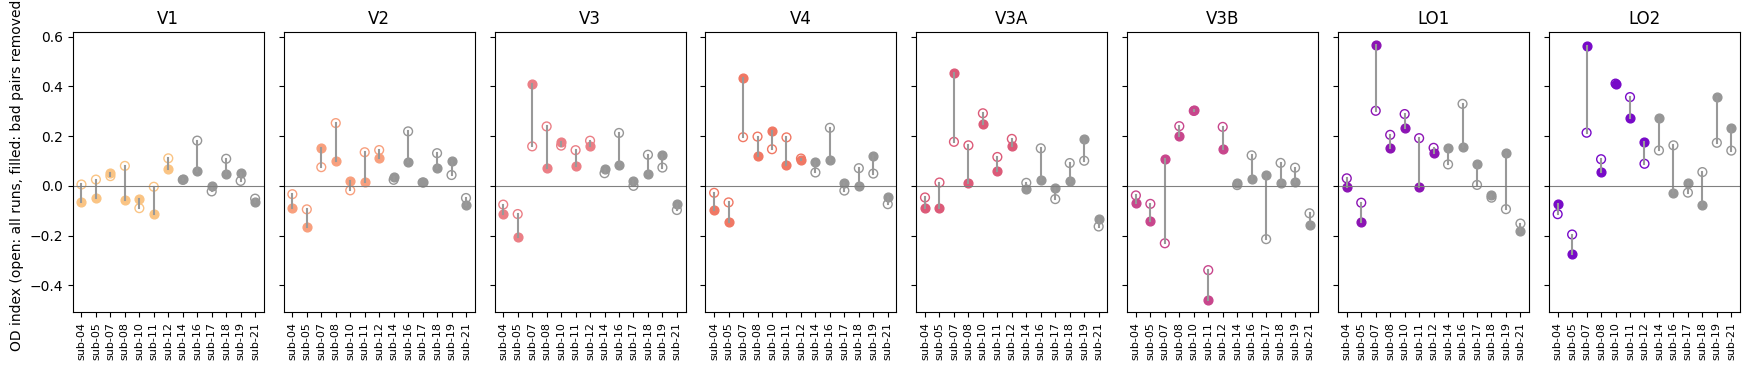

In [10]:
v = '{} - pair'.format(main_th)
changed = sorted(set(res[(res.version == v) & (res.n_runs_fe < 4)].subject), key=subj_order.index)
if changed:
    fig, axes = plt.subplots(1, len(rois_to_keep), figsize=(2.2 * len(rois_to_keep), 3.8), sharey=True)
    for ax, roi in zip(axes, rois_to_keep):
        for i, s in enumerate(changed):
            a = res[(res.version == 'none') & (res.subject == s) & (res.roi == roi)].od_index
            b = res[(res.version == v) & (res.subject == s) & (res.roi == roi)].od_index
            if len(a) and len(b):
                col = roi_colors_rgb[roi] if s in patients else ctrl_color
                col = tuple(int(x) / 255 for x in col.strip('rgb() ').split(','))
                ax.plot([i, i], [a.iloc[0], b.iloc[0]], color='0.6')
                ax.scatter(i, a.iloc[0], facecolors='none', edgecolors=col, s=40)
                ax.scatter(i, b.iloc[0], color=col, s=40)
        ax.axhline(0, color='grey', lw=0.8)
        ax.set_xticks(range(len(changed))); ax.set_xticklabels(changed, rotation=90, fontsize=8); ax.set_title(roi)
    axes[0].set_ylabel('OD index (open: all runs, filled: bad pairs removed)')
    plt.tight_layout(); fig.savefig('{}/runqc_Q2_od_change.pdf'.format(fig_dir), bbox_inches='tight'); plt.show()
else:
    print('No run excluded at the main threshold.')

## Reading guide

- **Q1**: are bad runs rare and isolated (a few runs, like sub-05 AE Bars01), or is a whole subject poor (sub-04: low everywhere, so no run stands out with a relative criterion)? Are they the first run of the session, or runs with more motion?
- **Group results**: if the stars of Figures 1-2 are unchanged with and without exclusion and across thresholds, the conclusions do not depend on run quality: keep all runs in the main analysis and report this control. If they change, discuss which version to adopt (decided on the criterion, not on the result).
- Decision to take **before** looking at the effect on the OD: threshold and rule (pair vs run). The main choice here is 50 % and pair, fixed in advance.
- If runs are excluded in the final analysis, the full pipeline should be rerun (pRF fit without these runs, then `make_od_img.py`, on the cluster).